In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Boston House Price Prediction Project Started!")
print("All libraries imported successfully!")

Boston House Price Prediction Project Started!
All libraries imported successfully!


Load Data Set 

In [3]:
df = pd.read_csv("../datasets/HousingData.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
#Display first 5 rows
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


In [6]:
#Check dataset shape
print("Dataset Shape:", df.shape)

#Dataset information
df.info()

Dataset Shape: (506, 14)
<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      486 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    486 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [7]:
#Missing values check

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
CRIM       20
ZN         20
INDUS      20
CHAS       20
NOX         0
RM          0
AGE        20
DIS         0
RAD         0
TAX         0
PTRATIO     0
B           0
LSTAT      20
MEDV        0
dtype: int64


In [9]:
# Create a copy of original dataset

df_clean = df.copy()

print("Dataset copy created successfully!")

Dataset copy created successfully!


In [11]:
# Fill numerical columns with median

numerical_columns = ['CRIM', 'ZN', 'INDUS', 'AGE', 'LSTAT']

for col in numerical_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())


# Fill CHAS with mode

df_clean['CHAS'] = df_clean['CHAS'].fillna(df_clean['CHAS'].mode()[0])

print("Missing values handled successfully!")

Missing values handled successfully!


In [13]:
print("Missing values after cleaning:")

print(df_clean.isnull().sum())

print("\nTotal Missing Values:",
      df_clean.isnull().sum().sum())

Missing values after cleaning:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

Total Missing Values: 0


In [15]:
# Statistical Summary

df_clean.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.479140,10.768775,11.028893,0.067194,0.554695,6.284634,68.845850,3.795043,9.549407,408.237154,18.455534,356.674032,12.664625,22.532806
std,8.570832,23.025124,6.704679,0.250605,0.115878,0.702617,27.486962,2.105710,8.707259,168.537116,2.164946,91.294864,7.017219,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.083235,0.000000,5.190000,0.000000,0.449000,5.885500,45.925000,2.100175,4.000000,279.000000,17.400000,375.377500,7.230000,17.025000
50%,0.253715,0.000000,9.690000,0.000000,0.538000,6.208500,76.800000,3.207450,5.000000,330.000000,19.050000,391.440000,11.430000,21.200000
75%,2.808720,0.000000,18.100000,0.000000,0.624000,6.623500,93.575000,5.188425,24.000000,666.000000,20.200000,396.225000,16.570000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


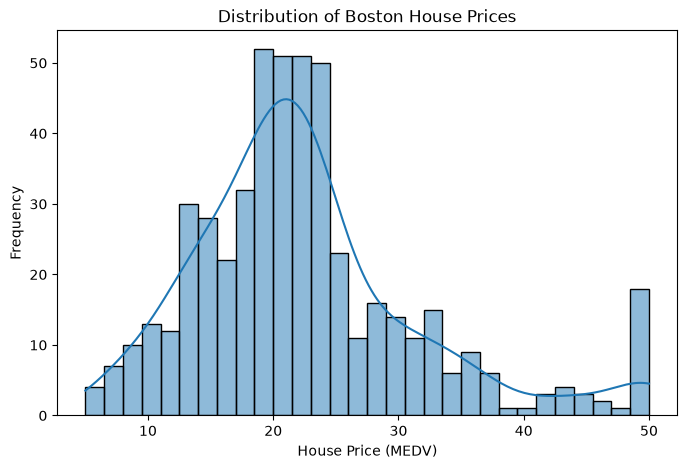

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(df_clean['MEDV'], bins=30, kde=True)

plt.title("Distribution of Boston House Prices")
plt.xlabel("House Price (MEDV)")
plt.ylabel("Frequency")

plt.show()

In [19]:
# Calculate correlation matrix

correlation = df_clean.corr()

print(correlation['MEDV'].sort_values(ascending=False))


MEDV       1.000000
RM         0.695360
ZN         0.362292
B          0.333461
DIS        0.249929
CHAS       0.183844
AGE       -0.377572
RAD       -0.381626
CRIM      -0.383895
NOX       -0.427321
TAX       -0.468536
INDUS     -0.476394
PTRATIO   -0.507787
LSTAT     -0.723093
Name: MEDV, dtype: float64


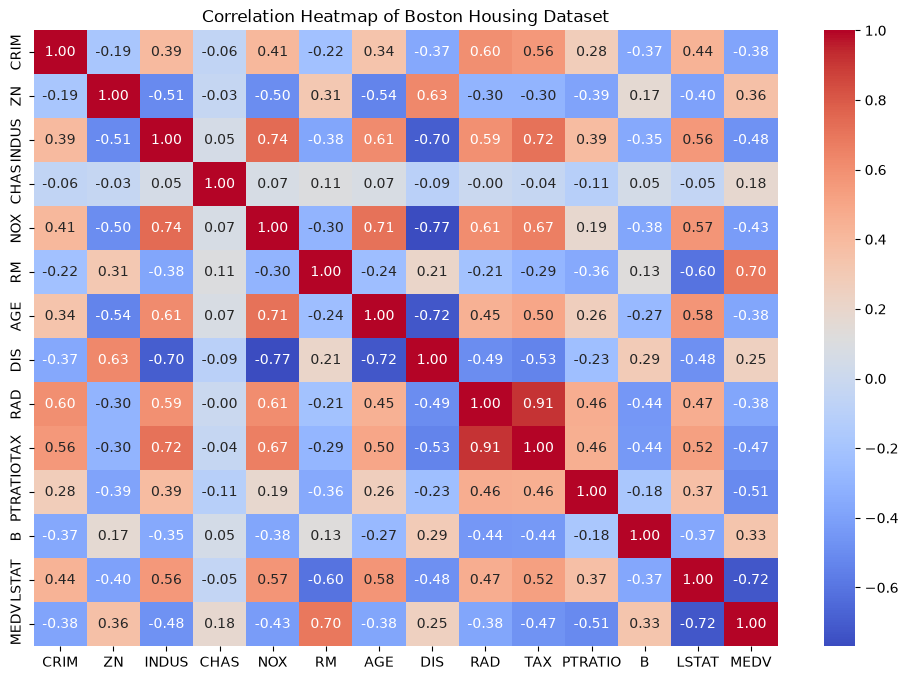

In [21]:
#Heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Boston Housing Dataset")

plt.show()

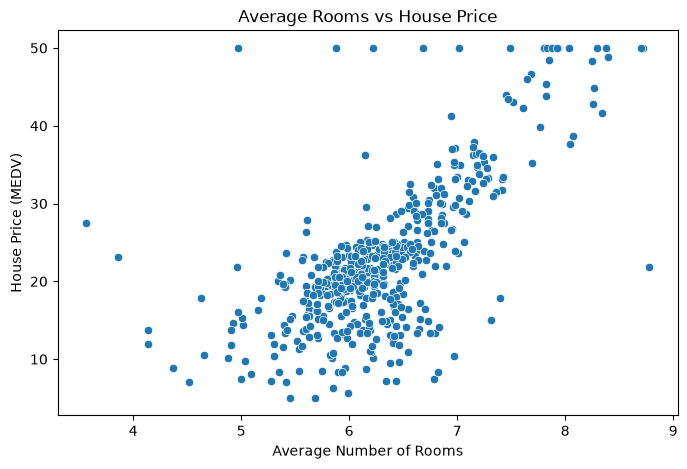

In [23]:
#RM vs MEDV

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='RM',
    y='MEDV',
    data=df_clean
)

plt.title("Average Rooms vs House Price")
plt.xlabel("Average Number of Rooms")
plt.ylabel("House Price (MEDV)")

plt.show()

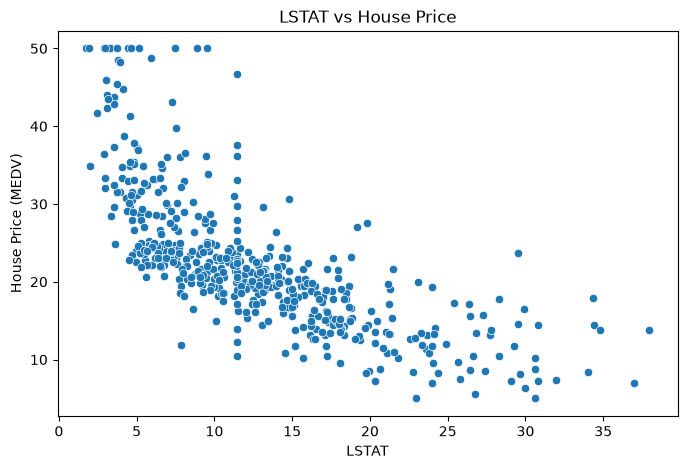

In [25]:
#LSTAT vs MEDV

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='LSTAT',
    y='MEDV',
    data=df_clean
)

plt.title("LSTAT vs House Price")
plt.xlabel("LSTAT")
plt.ylabel("House Price (MEDV)")

plt.show()

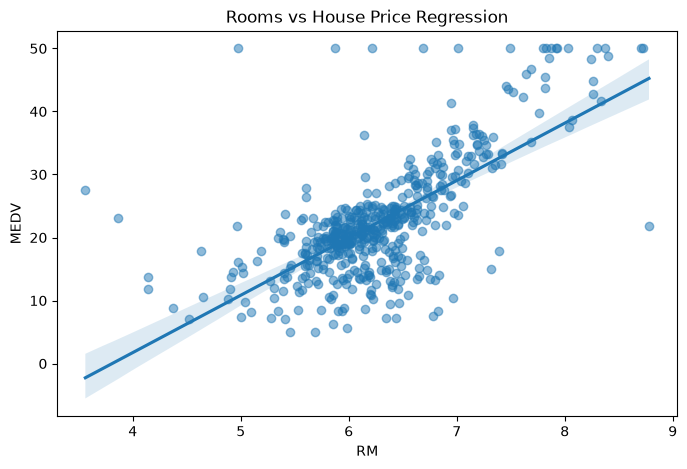

In [27]:
#RM vs MEDV Regression Plot

plt.figure(figsize=(8, 5))

sns.regplot(
    x='RM',
    y='MEDV',
    data=df_clean,
    scatter_kws={'alpha': 0.5}
)

plt.title("Rooms vs House Price Regression")
plt.show()

In [29]:
# Separate independent and dependent variables

X = df_clean.drop('MEDV', axis=1)

y = df_clean['MEDV']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (506, 13)
Target Shape: (506,)


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (404, 13)
Testing Data: (102, 13)


Prepare Training and Testing Data

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Separate features and target
X = df.drop('MEDV', axis=1)
y = df['MEDV']

# Identify columns
numerical_columns = X.columns.drop('CHAS').tolist()

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (404, 13)
Testing Data: (102, 13)


Handle Missing Values

In [32]:
# Preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'),
         numerical_columns),

        ('cat', SimpleImputer(strategy='most_frequent'),
         ['CHAS'])
    ]
)

print("Preprocessing completed!")

Preprocessing completed!


Model Selection (LinearRegression)

In [33]:
from sklearn.linear_model import LinearRegression

# Initialize model

lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

print("Linear Regression Model Initialized!")

Linear Regression Model Initialized!


Model Training

In [34]:
# Train the model

lr_model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


Make Predictions

In [35]:
# Predict house prices

y_pred = lr_model.predict(X_test)

print("Predictions generated successfully!")

print("\nActual Prices:")
print(y_test.values[:10])

print("\nPredicted Prices:")
print(y_pred[:10])

Predictions generated successfully!

Actual Prices:
[23.6 32.4 13.6 22.8 16.1 20.  17.8 14.  19.6 16.8]

Predicted Prices:
[29.04336056 36.51256944 14.53037225 25.04781746 18.38001498 23.02004816
 17.95284465 14.56617147 22.06933347 20.84723342]


Calculate MSE and R² Score

In [36]:
from sklearn.metrics import mean_squared_error, r2_score

# Calculate MSE
mse = mean_squared_error(y_test, y_pred)

# Calculate R2 Score
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
Mean Squared Error: 24.983445419913128
R2 Score: 0.6593187431051512


Actual vs Predicted Graph

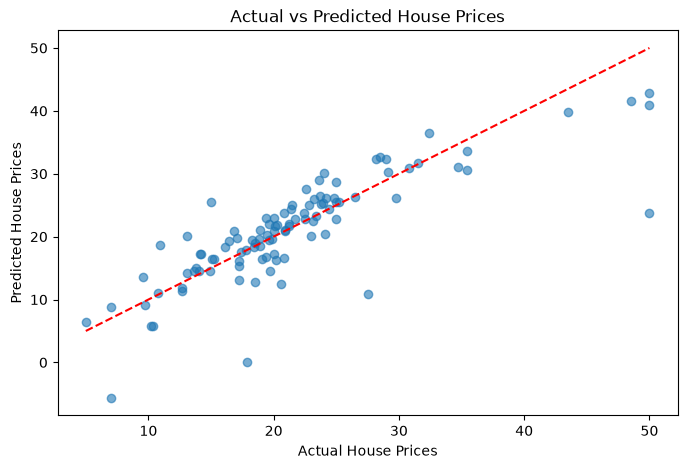

In [37]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()

Model creation (DecisionTreeRegressor)

In [38]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor(random_state=42))
])

print("Decision Tree model created successfully!")

Decision Tree model created successfully!


Model training

In [39]:
dt_model.fit(X_train, y_train)

print("Decision Tree model training completed!")

Decision Tree model training completed!


Model evaluation

In [40]:
from sklearn.metrics import mean_squared_error, r2_score

dt_pred = dt_model.predict(X_test)

dt_mse = mean_squared_error(y_test, dt_pred)
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Results")
print("MSE:", dt_mse)
print("R2 Score:", dt_r2)

Decision Tree Results
MSE: 23.88627450980392
R2 Score: 0.6742800728337779


Model creation (radientBoostingRegressor)

In [41]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(random_state=42))
])

print("Gradient Boosting model created successfully!")

Gradient Boosting model created successfully!


Model training

In [42]:
gb_model.fit(X_train, y_train)

print("Gradient Boosting model training completed!")

Gradient Boosting model training completed!


Evaluation

In [43]:
gb_pred = gb_model.predict(X_test)

gb_mse = mean_squared_error(y_test, gb_pred)
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting Results")
print("MSE:", gb_mse)
print("R2 Score:", gb_r2)

Gradient Boosting Results
MSE: 7.294999797394833
R2 Score: 0.9005233402257942


Final comparison table

In [44]:
import pandas as pd

results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Gradient Boosting'
    ],
    'MSE': [
        mse,
        dt_mse,
        gb_mse
    ],
    'R2 Score': [
        r2,
        dt_r2,
        gb_r2
    ]
})

results

,Model,MSE,R2 Score
0,Linear Regression,24.983445,0.659319
1,Decision Tree,23.886275,0.674280
2,Gradient Boosting,7.295000,0.900523


Save the best model

In [51]:
import joblib

loaded_model = joblib.load('../models/best_house_price_model.pkl')

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [52]:
sample_data = X_test.iloc[[0]]

prediction = loaded_model.predict(sample_data)

print("Actual House Price:", y_test.iloc[0])
print("Predicted House Price:", prediction[0])

Actual House Price: 23.6
Predicted House Price: 23.293751316800513


## Conclusion

In this project, we developed a Boston House Price Prediction model using Machine Learning.

The dataset was preprocessed by handling missing values. Exploratory Data Analysis (EDA) was performed to understand the relationships between different features and house prices.

Three regression models were implemented and evaluated:
- Linear Regression
- Decision Tree Regressor
- Gradient Boosting Regressor

After comparing the models, Gradient Boosting Regressor achieved the best performance.

**Final Model Results:**
- Mean Squared Error (MSE): 7.295
- R² Score: 0.9005

The trained model was saved using Joblib and successfully tested by loading it again and generating a sample prediction.

This project demonstrates the use of regression techniques for predicting house prices.